# BookScope: Exploratory Data Analysis of an Online Book Catalog

## 1. Introduction

### 1.1 Project Overview

BookScope is a Python-based web scraping and data analysis project
that extracts book information from Books to Scrape, a fictional
online bookstore designed for web scraping practice.

The project demonstrates an end-to-end data workflow, including
web scraping, data extraction, cleaning, transformation, and
exploratory data analysis (EDA).

The dataset contains information on 60 books collected from the
first three pages of the website.

### 1.2 Project Objectives

The primary objectives of this analysis are:

1. Examine the distribution of book prices.
2. Identify the five most expensive books in the dataset.
3. Analyze the distribution of book ratings.
4. Explore the association between book prices and ratings.

### 1.3 Dataset Description

The dataset was collected using Python, Requests, and Beautiful
Soup and subsequently processed using Pandas.

| Feature | Description |
|---------|-------------|
| title | Title of the book |
| price | Price of the book in GBP |
| rating | Book rating on a scale of 1–5 |
| availability | Stock availability status |
| product_url | URL of the book's product page |

**Data Source:** https://books.toscrape.com/

**Limitation:** The website contains synthetic data with randomly
assigned prices and ratings. Therefore, findings should be
interpreted as a demonstration of analytical techniques rather
than insights into actual book-market behavior.

## 2. Data Loading and Initial Inspection

This section loads the scraped dataset and examines its structure,
dimensions, and data types.

The initial inspection ensures that the dataset was successfully
exported during the web scraping process and is suitable for
subsequent analysis.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# Figure directory
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)

# Load dataset
df = pd.read_csv("data/books.csv")

# Display first five observations
display(df.head())

,title,price,rating,availability,product_url
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


In [8]:
print(f"Dataset Shape: {df.shape}")

print("\nDataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (60, 5)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         60 non-null     str    
 1   price         60 non-null     float64
 2   rating        60 non-null     int64  
 3   availability  60 non-null     str    
 4   product_url   60 non-null     str    
dtypes: float64(1), int64(1), str(3)
memory usage: 2.5 KB

Column Names:
['title', 'price', 'rating', 'availability', 'product_url']


## 3. Data Quality Assessment

Data quality assessment is conducted to evaluate the completeness,
consistency, and validity of the collected dataset.

The assessment focuses on:

- Missing values across all features.
- Duplicate book records based on product URLs.
- Data type consistency for numerical variables.
- Validity of the price and rating values.

These checks help ensure that subsequent analyses are performed
on reliable and appropriately structured data.

In [9]:
# Missing values
missing_values = df.isnull().sum()

print("Missing Values:")
display(missing_values.to_frame("Missing Count"))

# Duplicate records
duplicates = df.duplicated(subset=["product_url"]).sum()

print(f"\nDuplicate Book Records: {duplicates}")

# Check numerical data types
print("\nNumerical Data Types:")
print(df[["price", "rating"]].dtypes)

Missing Values:


,Missing Count
title,0
price,0
rating,0
availability,0
product_url,0



Duplicate Book Records: 0

Numerical Data Types:
price     float64
rating      int64
dtype: object


In [10]:
# Validate numerical values
print("Invalid Prices:", (df["price"] <= 0).sum())

print(
    "Invalid Ratings:",
    (~df["rating"].between(1, 5)).sum()
)

Invalid Prices: 0
Invalid Ratings: 0


### 3.1 Data Quality Findings

The assessment of the 60 book records found:

- **Missing values:** 0 in each of the five columns.
- **Duplicate records:** 0 duplicate product URLs.
- **Data type consistency:** `price` is stored as `float64` and `rating` as `int64`, so both are suitable for numerical analysis.
- **Invalid numerical values:** 0 prices at or below zero and 0 ratings outside the range of 1 to 5.

The dataset passes these checks and is suitable for exploratory data analysis without dropping records, imputing missing values, or converting the numerical columns. These checks cover completeness, URL uniqueness, and numerical validity; they do not verify the accuracy of every title or other text field.

## 4. Descriptive Statistical Analysis

Descriptive statistics are used to summarize the numerical
characteristics of the dataset.

The analysis focuses on book prices and includes the following
statistical measures:

- Mean: Average book price.
- Median: Middle value of the price distribution.
- Standard deviation: Degree of price variability.
- Minimum: Lowest observed price.
- Maximum: Highest observed price.
- Quartiles: Distribution of prices across different percentiles.

These measures provide an initial understanding of the price
distribution before further visualization.

In [11]:
# Descriptive statistics
price_stats = df["price"].describe()

display(price_stats.round(2))

count    60.00
mean     35.00
std      14.55
min      12.84
25%      22.04
50%      33.48
75%      50.14
max      57.31
Name: price, dtype: float64

In [12]:
print(f"Mean Price: £{df['price'].mean():.2f}")
print(f"Median Price: £{df['price'].median():.2f}")
print(f"Minimum Price: £{df['price'].min():.2f}")
print(f"Maximum Price: £{df['price'].max():.2f}")
print(f"Standard Deviation: £{df['price'].std():.2f}")

Mean Price: £35.00
Median Price: £33.48
Minimum Price: £12.84
Maximum Price: £57.31
Standard Deviation: £14.55


### 4.1 Descriptive Statistics Findings

Across the 60 books, the mean price is **£35.00** and the median is **£33.48**. Prices range from **£12.84** to **£57.31**, a spread of **£44.47**.

The standard deviation is **£14.55**, indicating substantial price variation relative to the mean. The middle 50% of prices fall between **£22.04** and **£50.14**, giving an interquartile range of approximately **£28.10**.

The mean exceeds the median by only **£1.52**. This small difference suggests limited overall skewness, but it does not establish a symmetric or bell-shaped distribution. The histogram below provides more detail about where prices cluster.

## 5. Exploratory Data Analysis

### 5.1 Distribution of Book Prices

**Research Question 1:** How are book prices distributed across
the scraped catalog?

A histogram is used to visualize the frequency distribution
of book prices.

This visualization helps identify:

- The most common price ranges.
- The overall spread of prices.
- Potential skewness in the distribution.
- Unusually high or low prices.

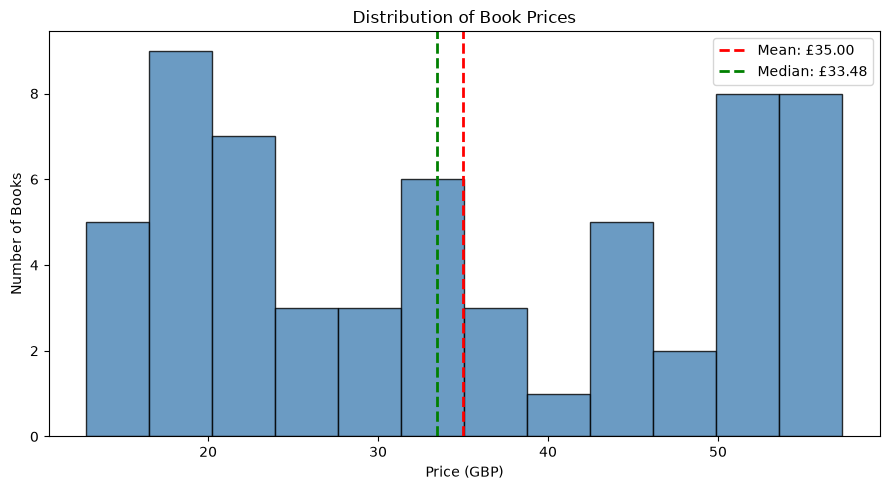

In [13]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["price"].dropna(),
    bins=12,
    color="steelblue",
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    df["price"].mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: £{df['price'].mean():.2f}"
)

plt.axvline(
    df["price"].median(),
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Median: £{df['price'].median():.2f}"
)

plt.title("Distribution of Book Prices")
plt.xlabel("Price (GBP)")
plt.ylabel("Number of Books")

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "price_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Findings: Price Distribution

The histogram shows a broad, uneven distribution across the 60 books, with concentrations at both the lower and upper ends of the price range. It does not show a single clear bell-shaped peak or a pronounced one-sided tail.

With the 12 bins used in the chart, the busiest interval is approximately **£16.55 to £20.25**, containing **9 books**. The two highest-price intervals, approximately **£49.90 to £53.60** and **£53.60 to £57.31**, each contain **8 books**. By comparison, only **1 book** falls in the interval from approximately **£38.78 to £42.49**. These patterns depend on the chosen bin boundaries.

The mean (**£35.00**) and median (**£33.48**) are close, consistent with limited overall skewness despite the uneven shape. The lowest price (**£12.84**) and highest price (**£57.31**) lie near other observations at their respective ends of the distribution, rather than appearing as isolated extremes. The histogram alone does not establish formal outlier status.

**Key Insight:** Prices span a wide range, with noticeable concentrations among cheaper books and books priced around £50 or more.

### 5.2 Identification of the Most Expensive Books

**Research Question 2:** Which five books have the highest
prices in the collected dataset?

To address this question, books are sorted by price in
descending order.

The five books with the highest prices are then selected
for comparison.

This analysis provides an overview of the upper end of
the observed price range.

In [14]:
top_5_expensive = (
    df.sort_values(
        by="price",
        ascending=False
    )
    .head(5)
)

display(
    top_5_expensive[
        ["title", "price", "rating"]
    ]
)

,title,price,rating
40,Slow States of Collapse: Poems,57.31,3
15,Our Band Could Be Your Life: Scenes from the A...,57.25,3
58,The Past Never Ends,56.50,4
57,The Pioneer Woman Cooks: Dinnertime: Comfort C...,56.41,1
56,The Secret of Dreadwillow Carse,56.13,1


C:\Users\farhan\AppData\Local\Temp\ipykernel_34372\3935804468.py:15: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


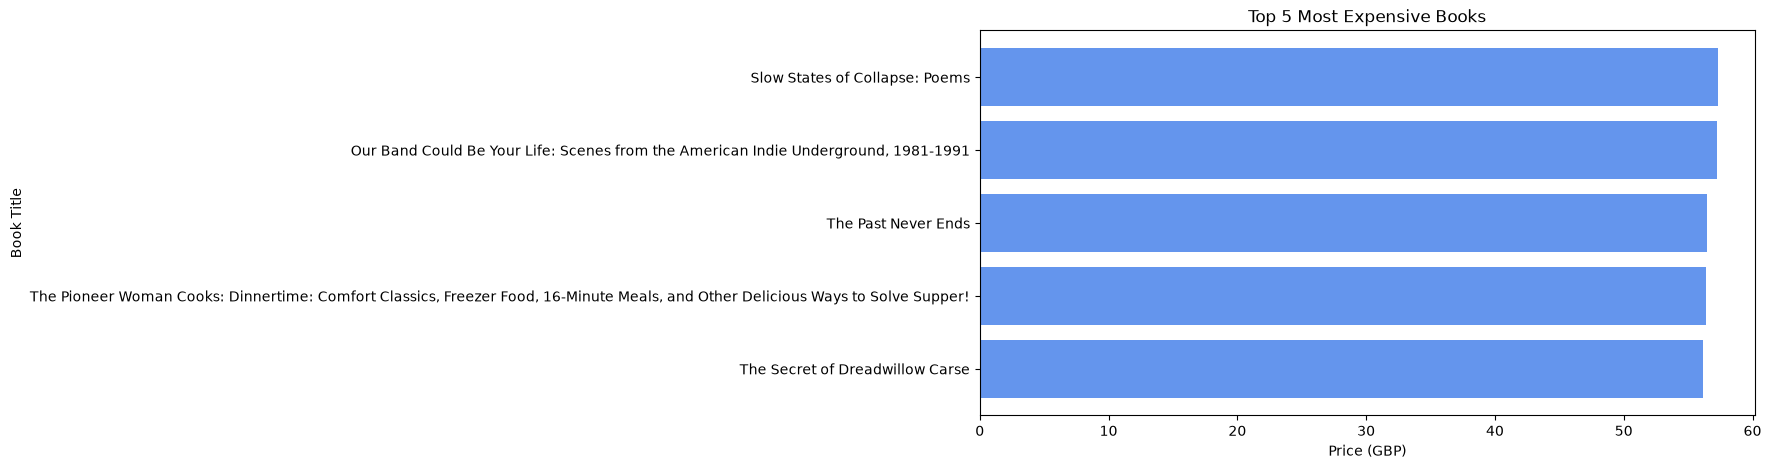

In [15]:
plt.figure(figsize=(10, 5))

plt.barh(
    top_5_expensive["title"],
    top_5_expensive["price"],
    color="cornflowerblue"
)

plt.gca().invert_yaxis()

plt.title("Top 5 Most Expensive Books")
plt.xlabel("Price (GBP)")
plt.ylabel("Book Title")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "top_5_expensive.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Findings: Most Expensive Books

The five highest-priced books are:

| Rank | Book | Price (GBP) | Rating |
|------|------|-------------|--------|
| 1 | Slow States of Collapse: Poems | £57.31 | 3 stars |
| 2 | Our Band Could Be Your Life: Scenes from the American Indie Underground, 1981-1991 | £57.25 | 3 stars |
| 3 | The Past Never Ends | £56.50 | 4 stars |
| 4 | The Pioneer Woman Cooks: Dinnertime: Comfort Classics, Freezer Food, 16-Minute Meals, and Other Delicious Ways to Solve Supper! | £56.41 | 1 star |
| 5 | The Secret of Dreadwillow Carse | £56.13 | 1 star |

**Slow States of Collapse: Poems** is the most expensive book at **£57.31**, only **£0.06** above the second-ranked book. The top five prices range from **£56.13 to £57.31**, a narrow spread of **£1.18**. All five are well above the overall mean of **£35.00**.

Their ratings range from 1 to 4 stars, showing that the highest-priced books do not all have high ratings.

**Key Insight:** The five most expensive books form a closely grouped price band near the sample maximum, despite having different star ratings.

### 5.3 Distribution of Book Ratings

**Research Question 3:** How are book ratings distributed
across the sampled catalog?

Book ratings are represented using an ordinal scale ranging
from one to five stars.

A frequency analysis is conducted to determine the number
of books belonging to each rating category.

The results are visualized using a bar chart to facilitate
comparison between rating categories.

In [16]:
rating_counts = (
    df["rating"]
    .value_counts()
    .reindex(range(1, 6), fill_value=0)
    .sort_index()
)

display(rating_counts.to_frame("Number of Books"))

,Number of Books
rating,
1,15
2,8
3,13
4,10
5,14


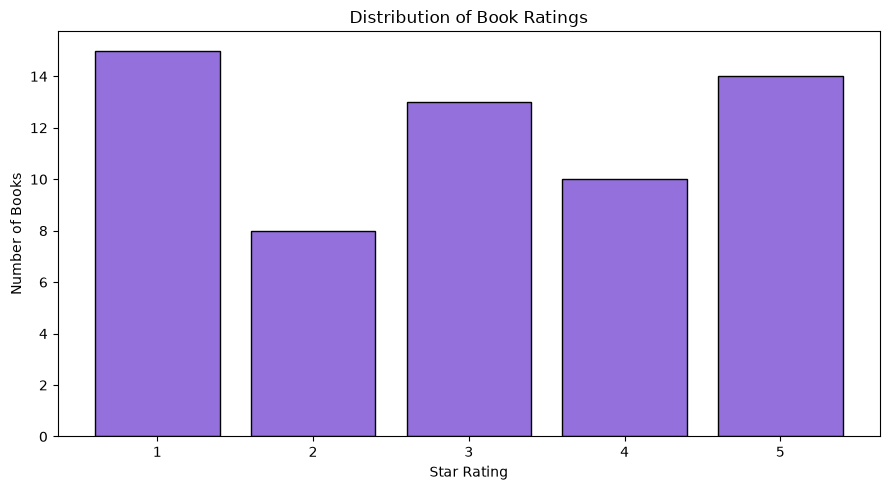

In [17]:
plt.figure(figsize=(9, 5))

plt.bar(
    rating_counts.index,
    rating_counts.values,
    color="mediumpurple",
    edgecolor="black"
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.xticks(range(1, 6))

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "rating_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Findings: Rating Distribution

All five rating categories are represented:

| Star rating | Number of books | Share of sample |
|-------------|-----------------|-----------------|
| 1 | 15 | 25.0% |
| 2 | 8 | 13.3% |
| 3 | 13 | 21.7% |
| 4 | 10 | 16.7% |
| 5 | 14 | 23.3% |

The most common category is **1 star**, with **15 books (25.0%)**, closely followed by **5 stars**, with **14 books (23.3%)**. The least common category is **2 stars**, with **8 books (13.3%)**.

The distribution is fairly spread across the scale, although the counts are not equal: the largest category contains 7 more books than the smallest. No single category accounts for more than a quarter of the sample.

**Key Insight:** Both ends of the rating scale are common, while 2-star books are least frequent.

Since ratings are randomly assigned by the source website, these findings do not represent actual consumer evaluations or satisfaction.

### 5.4 Relationship Between Book Prices and Ratings

**Research Question 4:** Is there an association between
book prices and star ratings?

This analysis investigates differences in book prices
across rating categories.

The following methods are applied:

1. Grouping books by rating.
2. Calculating the average and median prices for each group.
3. Visualizing average prices across rating categories.
4. Calculating Spearman's rank correlation coefficient.

Spearman's correlation is used as an exploratory measure
because ratings are ordinal.

The analysis is descriptive and does not establish
causality.

In [18]:
price_by_rating = (
    df.groupby("rating")["price"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(price_by_rating)

,count,mean,median,std
rating,,,,
1,15,34.31,31.77,15.79
2,8,33.87,35.48,13.48
3,13,38.81,33.29,14.91
4,10,35.53,38.76,15.35
5,14,32.48,29.90,14.27


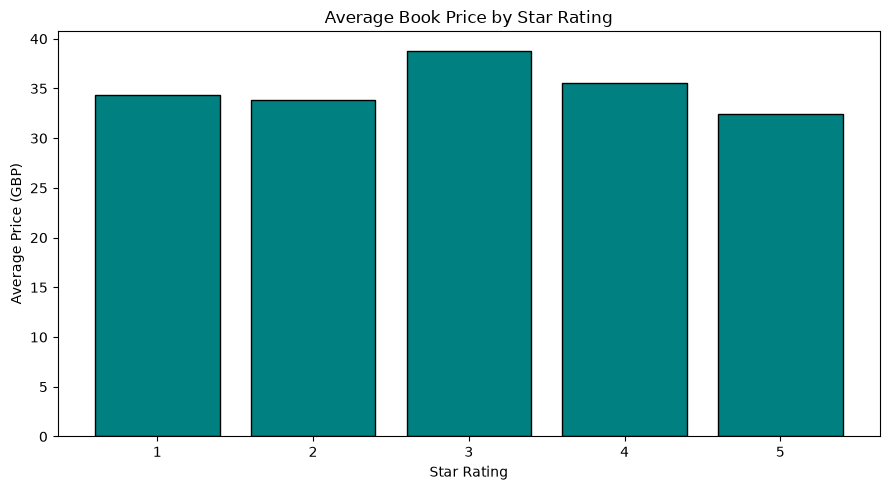

In [19]:
average_price = df.groupby("rating")["price"].mean()

plt.figure(figsize=(9, 5))

plt.bar(
    average_price.index,
    average_price.values,
    color="teal",
    edgecolor="black"
)

plt.title("Average Book Price by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Average Price (GBP)")

plt.xticks(range(1, 6))

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "price_by_rating.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
correlation = df[["price", "rating"]].corr(
    method="spearman"
)

display(correlation.round(3))

,price,rating
price,1.000,-0.044
rating,-0.044,1.000


In [21]:
corr_value = correlation.loc["price", "rating"]

print(f"Spearman Correlation: {corr_value:.3f}")

Spearman Correlation: -0.044


#### Findings: Price and Rating Relationship

Average prices vary across rating groups:

| Star rating | Number of books | Mean price (GBP) | Median price (GBP) |
|-------------|-----------------|------------------|--------------------|
| 1 | 15 | £34.31 | £31.77 |
| 2 | 8 | £33.87 | £35.48 |
| 3 | 13 | £38.81 | £33.29 |
| 4 | 10 | £35.53 | £38.76 |
| 5 | 14 | £32.48 | £29.90 |

Books rated **3 stars** have the highest average price (**£38.81**), while **5-star** books have the lowest (**£32.48**). The difference between these displayed averages is **£6.33**. The highest median belongs to the **4-star** group (**£38.76**), so the group ranking depends on the summary measure used.

Average prices do not consistently increase or decrease as ratings rise. Within-group standard deviations range from **£13.48 to £15.79**, indicating substantial price variation within every rating category.

Spearman's rank correlation coefficient is **−0.044**, indicating a negligible negative monotonic association in this sample. This coefficient does not establish causality or rule out every possible form of relationship, and no statistical significance test is reported.

**Key Insight:** Higher ratings are not consistently associated with higher prices in this sample; the observed rank correlation is close to zero.

The website uses synthetic prices and randomly assigned ratings, so these results should not be generalized to real-world book pricing or customer behavior.

## 6. Conclusion

### 6.1 Summary of Findings

This project demonstrated a complete workflow for collecting,
processing, and analyzing structured data from a website using
Python.

The analysis produced the following findings:

1. **Price Distribution:** Prices range from **£12.84 to £57.31**, with a mean of **£35.00**, a median of **£33.48**, and a standard deviation of **£14.55**. The histogram is uneven, with concentrations at lower and higher prices and limited overall skewness.

2. **Most Expensive Books:** **Slow States of Collapse: Poems** is the highest-priced book at **£57.31**. The top five books are closely grouped between **£56.13 and £57.31**, a spread of just **£1.18**.

3. **Rating Distribution:** **1 star** is the most common rating, with **15 books (25.0%)**, followed by **5 stars**, with **14 books (23.3%)**. **2 stars** is least common, with **8 books (13.3%)**. All five rating categories are represented.

4. **Price and Rating Relationship:** **3-star** books have the highest mean price (**£38.81**) and **5-star** books the lowest (**£32.48**). Mean prices do not follow a consistent trend across ratings, and Spearman's correlation of **−0.044** indicates a negligible monotonic association.

The data quality checks found no missing values, duplicate product URLs, non-positive prices, or ratings outside 1 to 5. All **60 records** were retained for analysis.

### 6.2 Project Limitations

Several limitations should be considered:

- The dataset consists of only 60 books from the first
  three pages of the catalog.
- The website contains synthetic prices and ratings.
- The analysis represents a single snapshot of the website.
- The findings cannot be generalized to the real-world
  publishing or retail industry.
- The scraper depends on the website's HTML structure,
  which may change over time.

### 6.3 Future Improvements

Potential improvements include:

1. Expanding the scraper to collect all 1,000 books.
2. Extracting additional information such as book categories.
3. Implementing more robust error handling and logging.
4. Automating data collection and validation.
5. Developing an interactive dashboard to explore the data.

### 6.4 Final Remarks

BookScope demonstrates how web scraping techniques can be
integrated with data cleaning, exploratory analysis, and
visualization to transform unstructured website content
into an analyzable dataset.

The primary contribution of this project is the implementation
of a reproducible data acquisition and analysis pipeline
using Python.